In [17]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver
import time

load_dotenv()


True

## Setup

The imports provide LangGraph's graph builder and in-memory checkpointer, the state typing helper, and `time` for the simulated pause. The next cell loads environment settings and configures a chat model; this persistence example does not call the model, so the graph itself does not depend on it.

In [18]:
load_dotenv()
llm = ChatGroq(
    model="openai/gpt-oss-20b"
)

## Define the graph state

`CrashState` describes the shared data carried between nodes. The initial invocation provides `input`; each step returns a partial update for its own field, and LangGraph merges that update into the state.

In [19]:
#1 Define the state
class CrashState(TypedDict):
    input: str
    step1: str
    step2: str
    step3: str

## Define the workflow steps

Each function is a graph node: it receives the current state and returns the fields it updates. `step2` pauses for 30 seconds so you have time to interrupt the running notebook cell; `step3` records its completion in the `step3` state field.

In [20]:
#2 Define steps
def step1(state: CrashState) -> CrashState:
    print("Step 1: Executed")
    return {"step1": "done", "input": state["input"]}

def step2(state: CrashState) -> CrashState:
    print("Step 2 hanging and then manually interrupt from the notebook toolbar")
    time.sleep(30)
    return {"step2": "done"}

def step3(state: CrashState) -> CrashState:
    print("Step 3: Executed")
    return {"step3": "done"}


## Build and compile the graph

The builder registers each function under a node name, connects the nodes in sequence, and marks the start and end. `InMemorySaver` stores checkpoints for the graph while this Python kernel is alive; compiling the builder creates the runnable graph.

In [21]:
#3 Build the gaph

builder = StateGraph(CrashState)
builder.add_node("step1", step1)
builder.add_node("step2", step2)
builder.add_node("step3", step3)

builder.add_edge(START, "step1")
builder.add_edge("step1", "step2")
builder.add_edge("step2", "step3")
builder.add_edge("step3", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

## Visualize the graph

Evaluating `graph` in a notebook displays its graph representation. This is just a visual check of the registered nodes and edges; it does not execute the workflow.

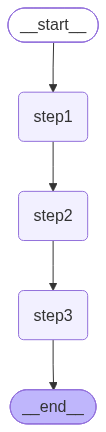

In [22]:
graph

## Run the graph and simulate an interruption

This starts a run on thread `"1"` with the initial input. When `step2` prints that it is waiting, interrupt the cell from the notebook toolbar before its 30-second sleep finishes. The checkpointer can then be inspected to see what was saved before the interruption.

In [23]:
try:
    print("Running graph please manually interrupt during step 2")
    graph.invoke({"input": "start"}, config={"configurable": {"thread_id": "1"}})
except KeyboardInterrupt:
    print("Kernel manually interrupted (crash simulated)")

Running graph please manually interrupt during step 2
Step 1: Executed
Step 2 hanging and then manually interrupt from the notebook toolbar
Kernel manually interrupted (crash simulated)


## Inspect the latest saved state

`get_state` returns the latest checkpoint for thread `"1"`. Check `values` for the saved state and `next` for the node LangGraph was about to run (if any). The displayed result may differ depending on exactly when you interrupted the run.

In [27]:
graph.get_state({"configurable": {"thread_id": "1"}})

StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caf3b-63fe-6bf2-8003-b731e433119c'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-10-18T12:59:10.870219+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caf3b-63f9-6dd5-8002-87ee447eb535'}}, tasks=(), interrupts=())

## Review the checkpoint history

`get_state_history` returns the thread's snapshots, newest first. Compare each snapshot's `values` and `next` fields to follow state changes and see which node was pending at each checkpoint.

In [28]:
list(graph.get_state_history({"configurable": {"thread_id": "1"}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caf3b-63fe-6bf2-8003-b731e433119c'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-10-18T12:59:10.870219+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caf3b-63f9-6dd5-8002-87ee447eb535'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done'}, next=('step3',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caf3b-63f9-6dd5-8002-87ee447eb535'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-18T12:59:10.868219+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caf38-f07e-661a-8001-189a74bad162'}}, tasks=(PregelTask(id='62cab3fd-dba4-1264-078d-d893b0b5cc50', name='st

## Resume from the saved checkpoint

Passing `None` as the input and reusing thread `"1"` resumes that thread from its latest checkpoint instead of starting a new run. If the interruption happened during `step2`, that node may run again because its successful result was not yet checkpointed; the following step then continues.

In [26]:
# Re-run to show fault tolerance.Resume from last checkpoint
final_state = graph.invoke(None,config={"configurable": {"thread_id": "1"}})
print("Final state after resuming from checkpoint:", final_state)

Step 2 hanging and then manually interrupt from the notebook toolbar
Step 3: Executed
Final state after resuming from checkpoint: {'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}


## Retrieve a specific historical checkpoint

The next cell asks for one checkpoint by its ID rather than the thread's latest snapshot. The ID shown is from an earlier execution: after restarting the kernel or running a new graph execution, copy an ID from the current history output here. Checkpoint IDs are unique and are not stable across runs.

In [29]:
graph.get_state({"configurable": {"thread_id": "1", "checkpoint_id": "1f1caf3b-63fe-6bf2-8003-b731e433119c"}})

StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_id': '1f1caf3b-63fe-6bf2-8003-b731e433119c'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-10-18T12:59:10.870219+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caf3b-63f9-6dd5-8002-87ee447eb535'}}, tasks=(), interrupts=())

## Invoke from a checkpoint ID

This passes the same checkpoint ID to `invoke`. Since this particular ID is for a completed state (`next=()`), there is no pending node to run, so the state is returned unchanged. To observe execution continuing from a checkpoint, use an ID whose snapshot has a non-empty `next` field.

In [30]:
graph.invoke(None,config={"configurable": {"thread_id": "1", "checkpoint_id": "1f1caf3b-63fe-6bf2-8003-b731e433119c"}})

{'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}

## Compare history after the checkpoint invocation

This displays the complete thread history again. Because the preceding invocation selected a historical checkpoint, LangGraph may record a new `fork` checkpoint; compare its `checkpoint_id`, `parent_config`, and `metadata['source']` with the earlier entries to see the branch.

In [31]:
list(graph.get_state_history({"configurable": {"thread_id": "1"}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caf6f-6952-6666-8004-be7b4d4cebb7'}}, metadata={'source': 'fork', 'step': 4, 'parents': {}}, created_at='2026-10-18T13:22:27.293143+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caf3b-63fe-6bf2-8003-b731e433119c'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caf3b-63fe-6bf2-8003-b731e433119c'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-10-18T12:59:10.870219+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caf3b-63f9-6dd5-8002-87ee447eb535'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'input': 's

### Update state and compare checkpoint IDs

`CrashState` has an `input` field (not `topic`), so this example changes `input` to `"samosa"`. `update_state` creates a new checkpoint based on the checkpoint ID you provide; the original checkpoint remains available for comparison. This updates saved state only and does not rerun the graph.

First, fetch the latest snapshot for thread `"1"` and save its `config`. That config includes the checkpoint ID that identifies the exact version of the state we are about to compare.

In [32]:
thread_config = {"configurable": {"thread_id": "1"}}
snapshot_before = graph.get_state(thread_config)
checkpoint_before = snapshot_before.config

print("Before update:")
print("Checkpoint ID:", checkpoint_before["configurable"]["checkpoint_id"])
print("State:", snapshot_before.values)


Before update:
Checkpoint ID: 1f1caf6f-6952-6666-8004-be7b4d4cebb7
State: {'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}


## Create and verify the updated checkpoint

`update_state` starts from the exact checkpoint in `checkpoint_before` and changes only `input` to `"samosa"`. It returns the config for the new checkpoint. The following reads compare the updated version with the original, demonstrating that history preserves the earlier state.

In [33]:
updated_config = graph.update_state(checkpoint_before, {"input": "samosa"})
snapshot_after = graph.get_state(updated_config)
snapshot_original = graph.get_state(checkpoint_before)

print("After update:")
print("New checkpoint ID:", updated_config["configurable"]["checkpoint_id"])
print("Updated state:", snapshot_after.values)
print("Original checkpoint still has:", snapshot_original.values)


After update:
New checkpoint ID: 1f1caf85-5690-6bd6-8005-f495ab244fe4
Updated state: {'input': 'samosa', 'step1': 'done', 'step2': 'done', 'step3': 'done'}
Original checkpoint still has: {'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}
